# Video-Based Sexual Harassment Detection: Fine-Tuning ViViT

**Authors:** Jubayer Al Mahmud\*, Md Shamimul Islam\*, Md Nur Hossain (\* equal contribution, co-first authors)

Code for the paper *Video-Based Sexual Harassment Detection Using Fine-Tuned Video Transformers*, IEEE 3rd International Conference on Computing, Applications and Systems (COMPAS 2026), University of Dhaka, Bangladesh. [arXiv:2610.15354](https://arxiv.org/abs/2610.15354)

This notebook fine-tunes `google/vivit-b-16x2-kinetics400` (pretrained on Kinetics-400) for binary classification (Harassment / Non_Harassment) on the extended SHV dataset. It was run on Google Colab with a GPU.

## Step 1: Install Libraries and Load the Pretrained Model

In [ ]:
!pip install decord

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 29.7 MB/s eta 0:00:00


In [ ]:
from transformers import VivitImageProcessor, VivitForVideoClassification

In [ ]:
# Load image processor (equivalent to feature extractor) and pretrained model
feature_extractor = VivitImageProcessor.from_pretrained("google/vivit-b-16x2-kinetics400")
model = VivitForVideoClassification.from_pretrained("google/vivit-b-16x2-kinetics400")

## Step 2: Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

# Path to the zip file in Drive
zip_path = "/content/drive/MyDrive/ModelTrain/Sexual_Harassment/dataset/Sexual_Harassment_Dataset.zip"

# Unzip it to /content/
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/Sexual_Harassment_Dataset")

# Set dataset path
dataset_path = "/content/Sexual_Harassment_Dataset"

In [ ]:
import os

# List top-level files/folders
print(os.listdir("/content/Sexual_Harassment_Dataset"))

# If it's nested, explore further:
for root, dirs, files in os.walk("/content/Sexual_Harassment_Dataset"):
    print("Root:", root)
    print("Dirs:", dirs)
    print("Files:", files[:5])  # just print the first 5 files
    print("===")

['Sexual_Harassment_Dataset']
Root: /content/Sexual_Harassment_Dataset
Dirs: ['Sexual_Harassment_Dataset']
Files: []
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset
Dirs: ['test', 'train']
Files: []
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test
Dirs: ['Non_Harassment', 'Harassment']
Files: []
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Non_Harassment
Dirs: []
Files: ['no_haras_250.mp4', 'no_haras_5.mp4', 'no_haras_157.mp4', 'no_haras_208.mp4', 'no_haras_253.mp4']
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Harassment
Dirs: []
Files: ['haras_177.mp4', 'haras_85.mp4', 'haras_255.mp4', 'haras_196.mp4', 'haras_56.mp4']
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/train
Dirs: ['Non_Harassment', 'Harassment']
Files: []
===
Root: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/train/Non_Harassment
Dirs: []
Files: ['no_haras_183.mp4', 'no_h

In [ ]:
import os
from decord import VideoReader, cpu

dataset_path = "/content/Sexual_Harassment_Dataset/"

def count_unreadable_videos(root_dir):
    unreadable = []
    total = 0

    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file.lower().endswith(".mp4"):
                total += 1
                video_path = os.path.join(root, file)

                try:
                    vr = VideoReader(video_path, ctx=cpu(0))
                    if len(vr) == 0:
                        unreadable.append(video_path)
                except:
                    unreadable.append(video_path)

    print(f"Total videos found: {total}")
    print(f"Unreadable videos: {len(unreadable)}\n")

    if unreadable:
        print("List of unreadable videos:")
        for path in unreadable:
            print(path)

count_unreadable_videos(dataset_path)

Total videos found: 600
Unreadable videos: 0



In [ ]:
import os

dataset_path_updated = "/content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset"

def count_videos_in_classes(root_dir):
    class_counts = {}
    for split_dir_name in os.listdir(root_dir):
        split_dir_path = os.path.join(root_dir, split_dir_name)
        if os.path.isdir(split_dir_path):
            for class_name in os.listdir(split_dir_path):
                class_dir = os.path.join(split_dir_path, class_name)
                if os.path.isdir(class_dir):
                    if class_name not in class_counts:
                        class_counts[class_name] = 0
                    video_count = 0
                    for root, dirs, files in os.walk(class_dir):
                        for file in files:
                            if file.lower().endswith(".mp4"):
                                video_count += 1
                    class_counts[class_name] += video_count
    return class_counts

class_video_counts = count_videos_in_classes(dataset_path_updated)

print("Video counts per class:")
for class_name, count in class_video_counts.items():
    print(f"- {class_name}: {count}")

Video counts per class:
- Non_Harassment: 318
- Harassment: 282


In [ ]:
import os
from decord import VideoReader, cpu

def get_video_paths_labels(split_dir, label_map):
    video_paths = []
    labels = []
    unreadable_videos_count = 0

    for cls in label_map:
        cls_folder = os.path.join(split_dir, cls)

        if not os.path.isdir(cls_folder):
            print(f"Warning: Class folder not found: {cls_folder}. Skipping.")
            continue

        for fname in os.listdir(cls_folder):
            if fname.lower().endswith('.mp4'):
                video_path = os.path.join(cls_folder, fname)

                try:
                    vr = VideoReader(video_path, ctx=cpu(0))
                    _ = len(vr)

                    video_paths.append(video_path)
                    labels.append(label_map[cls])

                except Exception as e:
                    print(f"Warning: Could not read video {video_path}. Skipping. Error: {e}")
                    unreadable_videos_count += 1

    print(f"\n[{os.path.basename(split_dir)}] Unreadable videos skipped: {unreadable_videos_count}")
    return video_paths, labels


def load_dataset(base_dataset_dir):
    label_map = {'Non_Harassment': 0, 'Harassment': 1}

    train_dir = os.path.join(base_dataset_dir, 'train')
    test_dir = os.path.join(base_dataset_dir, 'test')

    print("Loading TRAIN data...")
    train_paths, train_labels = get_video_paths_labels(train_dir, label_map)

    print("\nLoading TEST data...")
    test_paths, test_labels = get_video_paths_labels(test_dir, label_map)

    return train_paths, train_labels, test_paths, test_labels, label_map


# مسیر (path)
base_dataset_dir = "/content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset"

train_paths, train_labels, test_paths, test_labels, label_map = load_dataset(base_dataset_dir)

# Summary
print("\n===== DATA SUMMARY =====")
print(f"Train videos: {len(train_paths)}")
print(f"Train labels: {len(train_labels)}")
print(f"Test videos: {len(test_paths)}")
print(f"Test labels: {len(test_labels)}")
print(f"Label mapping: {label_map}")

# Sanity check
print("\nFirst 3 TRAIN samples:")
for i in range(min(3, len(train_paths))):
    print(f"Path: {train_paths[i]}, Label: {train_labels[i]}")

print("\nFirst 3 TEST samples:")
for i in range(min(3, len(test_paths))):
    print(f"Path: {test_paths[i]}, Label: {test_labels[i]}")

Loading TRAIN data...

[train] Unreadable videos skipped: 0

Loading TEST data...

[test] Unreadable videos skipped: 0

===== DATA SUMMARY =====
Train videos: 419
Train labels: 419
Test videos: 181
Test labels: 181
Label mapping: {'Non_Harassment': 0, 'Harassment': 1}

First 3 TRAIN samples:
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/train/Non_Harassment/no_haras_183.mp4, Label: 0
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/train/Non_Harassment/no_haras_109.mp4, Label: 0
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/train/Non_Harassment/no_haras_258.mp4, Label: 0

First 3 TEST samples:
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Non_Harassment/no_haras_250.mp4, Label: 0
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Non_Harassment/no_haras_5.mp4, Label: 0
Path: /content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Non_Harassment/no_haras_157.mp4, Label: 0

## Step 3: Dataset Loader

In [ ]:
from torch.utils.data import Dataset
from decord import VideoReader, cpu
import numpy as np
from torchvision import transforms
from PIL import Image
import torch

class HarassmentDataset(Dataset):
    def __init__(self, video_paths, labels, feature_extractor, num_frames=32, is_train=True):
        self.video_paths = video_paths
        self.labels = labels
        self.feature_extractor = feature_extractor
        self.num_frames = num_frames
        self.is_train = is_train

        # Training augmentation
        self.train_transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.RandomRotation(5),
            transforms.ToTensor()
        ])

        # Validation / Test transform (deterministic)
        self.val_transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        vr = VideoReader(self.video_paths[idx], ctx=cpu(0))
        total_frames = len(vr)

        if total_frames == 0:
            raise ValueError(f"Empty video: {self.video_paths[idx]}")

        # Uniform sampling indices
        if total_frames >= self.num_frames:
            indices = np.linspace(0, total_frames - 1, self.num_frames, dtype=int)
        else:
            indices = np.arange(total_frames)
            pad_count = self.num_frames - total_frames
            indices = np.concatenate([indices, np.full(pad_count, total_frames - 1)])

        # Load selected frames as numpy (HWC, uint8)
        frames = vr.get_batch(indices).asnumpy()

        # Apply transform frame by frame
        if self.is_train:
            frames = [self.train_transform(frame) for frame in frames]
        else:
            frames = [self.val_transform(frame) for frame in frames]

        # Convert tensor frames back to PIL/NumPy for feature extractor
        processed_frames = [
            Image.fromarray((frame.permute(1, 2, 0).numpy() * 255).astype(np.uint8))
            for frame in frames
        ]

        # Feed list of processed frames to feature extractor
        inputs = self.feature_extractor(
            images=processed_frames,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].squeeze(0)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return pixel_values, label

In [ ]:
from torch.utils.data import DataLoader

train_dataset = HarassmentDataset(
    train_paths, train_labels, feature_extractor, num_frames=32, is_train=True
)

val_dataset = HarassmentDataset(
    test_paths, test_labels, feature_extractor, num_frames=32, is_train=False
)

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=2)

In [ ]:
for i, (pixel_values, labels) in enumerate(train_loader):
    print(f"Batch {i+1}")
    print("Pixel values shape:", pixel_values.shape)  # Should be (B, T, C, H, W) or (B, 3, 16, 224, 224) after permute
    print("Labels:", labels)
    if i == 1:  # print only first 2 batches
        break

Batch 1
Pixel values shape: torch.Size([2, 32, 3, 224, 224])
Labels: tensor([1, 0])
Batch 2
Pixel values shape: torch.Size([2, 32, 3, 224, 224])
Labels: tensor([1, 0])


In [ ]:
for i, (pixel_values, labels) in enumerate(val_loader):
    print(f"Validation Batch {i+1}")
    print("Pixel values shape:", pixel_values.shape)
    print("Labels:", labels)
    if i == 1:
        break

Validation Batch 1
Pixel values shape: torch.Size([2, 32, 3, 224, 224])
Labels: tensor([0, 0])
Validation Batch 2
Pixel values shape: torch.Size([2, 32, 3, 224, 224])
Labels: tensor([0, 0])


In [ ]:
print(pixel_values.shape)

torch.Size([2, 32, 3, 224, 224])


In [ ]:
print(f"Number of training videos: {len(train_dataset)}")
print(f"Number of validation videos: {len(val_dataset)}")

Number of training videos: 419
Number of validation videos: 181


In [ ]:
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")

Number of training batches: 210
Number of validation batches: 91


In [ ]:
print(f"Number of classes: {len(label_map)}")
print(f"Label map: {label_map}")

Number of classes: 2
Label map: {'Non_Harassment': 0, 'Harassment': 1}


## Step 4: Adjust the Model Output Layer

In [ ]:
import torch.nn as nn

num_classes = len(label_map)
model.classifier = nn.Linear(model.classifier.in_features, num_classes)
model.config.num_labels = num_classes

In [ ]:
print(f"Model name: {model.config._name_or_path}")

Model name: google/vivit-b-16x2-kinetics400


## Step 5: Training

In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import classification_report
from tqdm import tqdm
import os

# =====================
# Device
# =====================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
print(f"Using device: {device}")

# =====================
# Loss & Optimizer
# =====================
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=1e-5, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.1, patience=3)

# =====================
# Settings
# =====================
num_epochs = 20

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

idx_to_class = {v: k for k, v in label_map.items()}

# =====================
# Paths
# =====================
checkpoint_dir = "/content/drive/MyDrive/ModelTrain/Sexual_Harassment/checkpoints/New1"
os.makedirs(checkpoint_dir, exist_ok=True)

latest_ckpt = os.path.join(checkpoint_dir, "last_checkpoint.pth")
best_model_path = os.path.join(checkpoint_dir, "best_model.pth")

# =====================
# Resume Training
# =====================
start_epoch = 0
best_val_loss = float("inf")

if os.path.exists(latest_ckpt):
    checkpoint = torch.load(latest_ckpt, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if "scheduler_state_dict" in checkpoint:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_loss = checkpoint.get("best_val_loss", float("inf"))

    train_losses = checkpoint.get("train_losses", [])
    val_losses = checkpoint.get("val_losses", [])
    train_accuracies = checkpoint.get("train_accuracies", [])
    val_accuracies = checkpoint.get("val_accuracies", [])

    print(f"Resumed from epoch {start_epoch}")

# =====================
# Training Loop
# =====================
for epoch in range(start_epoch, num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")

    # ---- TRAIN ----
    model.train()
    running_loss, correct, total = 0, 0, 0

    for pixel_values, labels in tqdm(train_loader, desc="Training"):
        pixel_values, labels = pixel_values.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=pixel_values)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs

        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, pred = torch.max(logits, 1)

        total += labels.size(0)
        correct += pred.eq(labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # ---- VALIDATION ----
    model.eval()
    val_loss_total, correct, total = 0, 0, 0
    true_labels, pred_labels = [], []

    with torch.no_grad():
        for pixel_values, labels in tqdm(val_loader, desc="Validating"):
            pixel_values, labels = pixel_values.to(device), labels.to(device)

            outputs = model(pixel_values=pixel_values)
            logits = outputs.logits if hasattr(outputs, "logits") else outputs

            loss = criterion(logits, labels)
            val_loss_total += loss.item()

            _, pred = torch.max(logits, 1)

            total += labels.size(0)
            correct += pred.eq(labels).sum().item()

            true_labels.extend(labels.cpu().numpy())
            pred_labels.extend(pred.cpu().numpy())

    val_loss = val_loss_total / len(val_loader)
    val_acc = 100 * correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

    # ---- Scheduler ----
    scheduler.step(val_loss)
    print(f"LR: {optimizer.param_groups[0]['lr']:.8f}")

    # ---- Save BEST MODEL ----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        print("Best model updated!")

    # ---- Save MODEL ONLY (EVERY EPOCH) ----
    model_path = os.path.join(checkpoint_dir, f"model_epoch_{epoch+1}.pth")
    torch.save(model.state_dict(), model_path)

    # ---- Save LAST CHECKPOINT (for resume) ----
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracies": train_accuracies,
        "val_accuracies": val_accuracies,
        "best_val_loss": best_val_loss
    }, latest_ckpt)

    print(f"Saved model_epoch_{epoch+1}.pth + updated last checkpoint")

    # ---- Classification Report ----
    print("\nClassification Report:")
    print(classification_report(
        [idx_to_class[i] for i in true_labels],
        [idx_to_class[i] for i in pred_labels],
        digits=3,
        zero_division=0
    ))

print("\nTraining Finished!")

Using device: cuda
Resumed from epoch 20

Training Finished!


In [ ]:
import torch
import os
import pandas as pd

# =====================
# Paths
# =====================
checkpoint_dir = "/content/drive/MyDrive/ModelTrain/Sexual_Harassment/checkpoints/New1"
latest_ckpt = os.path.join(checkpoint_dir, "last_checkpoint.pth")

# =====================
# Load Checkpoint
# =====================
if os.path.exists(latest_ckpt):
    print(f"Loading checkpoint: {latest_ckpt}")
    checkpoint = torch.load(latest_ckpt, map_location='cpu')  # Use CPU for safety

    start_epoch = checkpoint.get("epoch", 0) + 1
    best_val_loss = checkpoint.get("best_val_loss", float("inf"))

    train_losses = checkpoint.get("train_losses", [])
    val_losses = checkpoint.get("val_losses", [])
    train_accuracies = checkpoint.get("train_accuracies", [])
    val_accuracies = checkpoint.get("val_accuracies", [])

    print(f"\nTraining History Summary")
    print(f"   Best Validation Loss : {best_val_loss:.4f}")
    print(f"   Total epochs recorded: {len(train_losses)}\n")

    # =====================
    # Print Detailed History Table
    # =====================
    print("Epoch-wise Training History:")
    print("-" * 85)
    print(f"{'Epoch':<6} {'Train Loss':<12} {'Val Loss':<12} {'Train Acc':<12} {'Val Acc':<12} {'Best?':<8}")
    print("-" * 85)

    best_epoch = -1
    best_loss = float("inf")

    for epoch in range(len(train_losses)):
        is_best = val_losses[epoch] < best_loss
        if is_best:
            best_loss = val_losses[epoch]
            best_epoch = epoch + 1

        print(f"{epoch+1:<6} "
              f"{train_losses[epoch]:<12.4f} "
              f"{val_losses[epoch]:<12.4f} "
              f"{train_accuracies[epoch]:<12.2f}% "
              f"{val_accuracies[epoch]:<12.2f}% "
              f"{'Best' if is_best else '':<8}")

    print("-" * 85)
    print(f"→ Best model was at Epoch {best_epoch} with Val Loss: {best_loss:.4f}")

    # =====================
    # Optional: Save as CSV for better viewing
    # =====================
    history_dict = {
        'Epoch': list(range(1, len(train_losses) + 1)),
        'Train_Loss': train_losses,
        'Val_Loss': val_losses,
        'Train_Acc': train_accuracies,
        'Val_Acc': val_accuracies
    }

    df = pd.DataFrame(history_dict)
    csv_path = os.path.join(checkpoint_dir, "training_history.csv")
    df.to_csv(csv_path, index=False)
    print(f"\nTraining history also saved as CSV: {csv_path}")

else:
    print(f"Checkpoint file not found: {latest_ckpt}")

Loading checkpoint: /content/drive/MyDrive/ModelTrain/Sexual_Harassment/checkpoints/New1/last_checkpoint.pth

Training History Summary
   Best Validation Loss : 0.2474
   Total epochs recorded: 20

Epoch-wise Training History:
-------------------------------------------------------------------------------------
Epoch  Train Loss   Val Loss     Train Acc    Val Acc      Best?   
-------------------------------------------------------------------------------------
1      0.5712       0.4477       69.69       % 80.11       % Best  
2      0.2409       0.3003       92.12       % 88.95       % Best  
3      0.1246       0.5437       96.66       % 75.69       %         
4      0.0521       0.2474       99.28       % 91.16       % Best  
5      0.0156       0.2737       100.00      % 89.50       %         
6      0.0065       0.2672       100.00      % 89.50       %         
7      0.0040       0.2711       100.00      % 88.95       %         
8      0.0027       0.2875       100.00      % 88

In [ ]:
best_model = "/content/drive/MyDrive/ModelTrain/Sexual_Harassment/checkpoints/New1/best_model.pth"

In [ ]:
# Make sure num_classes is still set correctly
model.classifier = nn.Linear(model.classifier.in_features, num_classes)
model.load_state_dict(torch.load(best_model))
model.eval()
model.to(device)

VivitForVideoClassification(
  (vivit): VivitModel(
    (embeddings): VivitEmbeddings(
      (patch_embeddings): VivitTubeletEmbeddings(
        (projection): Conv3d(3, 768, kernel_size=(2, 16, 16), stride=(2, 16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): VivitEncoder(
      (layer): ModuleList(
        (0-11): 12 x VivitLayer(
          (attention): VivitAttention(
            (attention): VivitSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): VivitSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): VivitIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bi

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Evaluation function
def evaluate(model, dataloader, label_map, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    val_loss = 0
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for pixel_values, labels in dataloader:
            pixel_values = pixel_values.to(device)
            labels = labels.to(device)

            outputs = model(pixel_values=pixel_values)
            loss = criterion(outputs.logits, labels)
            val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            true_labels.extend(labels.cpu().numpy())
            pred_labels.extend(preds.cpu().numpy())

    avg_loss = val_loss / len(dataloader)
    accuracy = accuracy_score(true_labels, pred_labels)

    # Convert index to class names
    idx_to_class = {v: k for k, v in label_map.items()}
    true_class_names = [idx_to_class[i] for i in true_labels]
    pred_class_names = [idx_to_class[i] for i in pred_labels]

    # Classification report
    report = classification_report(true_class_names, pred_class_names, digits=3)

    return avg_loss, accuracy, report, true_class_names, pred_class_names

## Step 6: Evaluation on the Test Set

Validation Accuracy: 91.16%
Validation Loss: 0.2473

Classification Report:
                precision    recall  f1-score   support

    Harassment      0.960     0.847     0.900        85
Non_Harassment      0.877     0.969     0.921        96

      accuracy                          0.912       181
     macro avg      0.919     0.908     0.910       181
  weighted avg      0.916     0.912     0.911       181



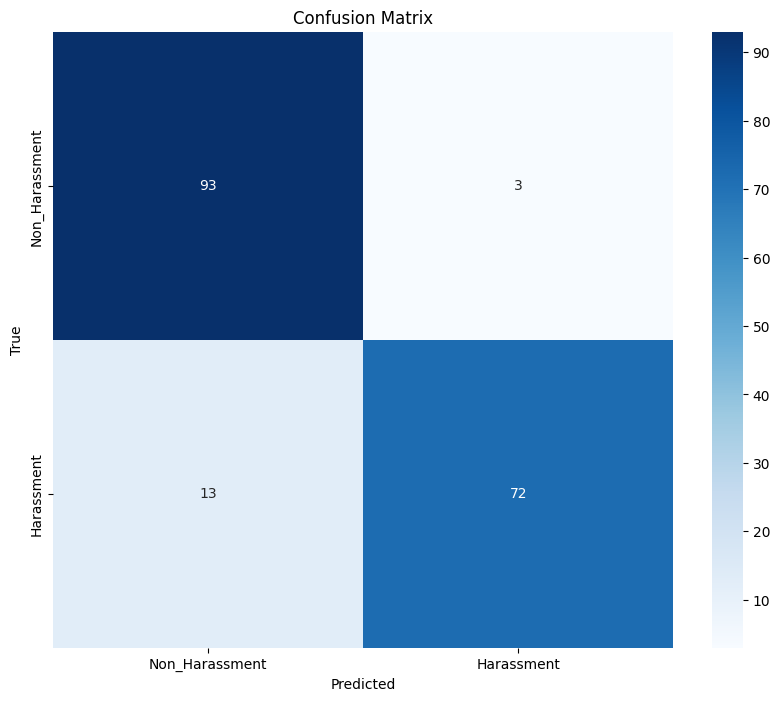

In [ ]:
# Load best model
model.load_state_dict(torch.load(best_model))
model.to(device)
model.eval()

# Run evaluation
avg_test_loss, test_acc, report, true_class_names, pred_class_names = evaluate(model, val_loader, label_map, device)

# Print results
print(f"Validation Accuracy: {test_acc * 100:.2f}%")
print(f"Validation Loss: {avg_test_loss:.4f}")
print("\nClassification Report:")
print(report)

# Plot Confusion Matrix
idx_to_class = {v: k for k, v in label_map.items()}
class_names = list(idx_to_class.values())

cm = confusion_matrix(true_class_names, pred_class_names, labels=class_names)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

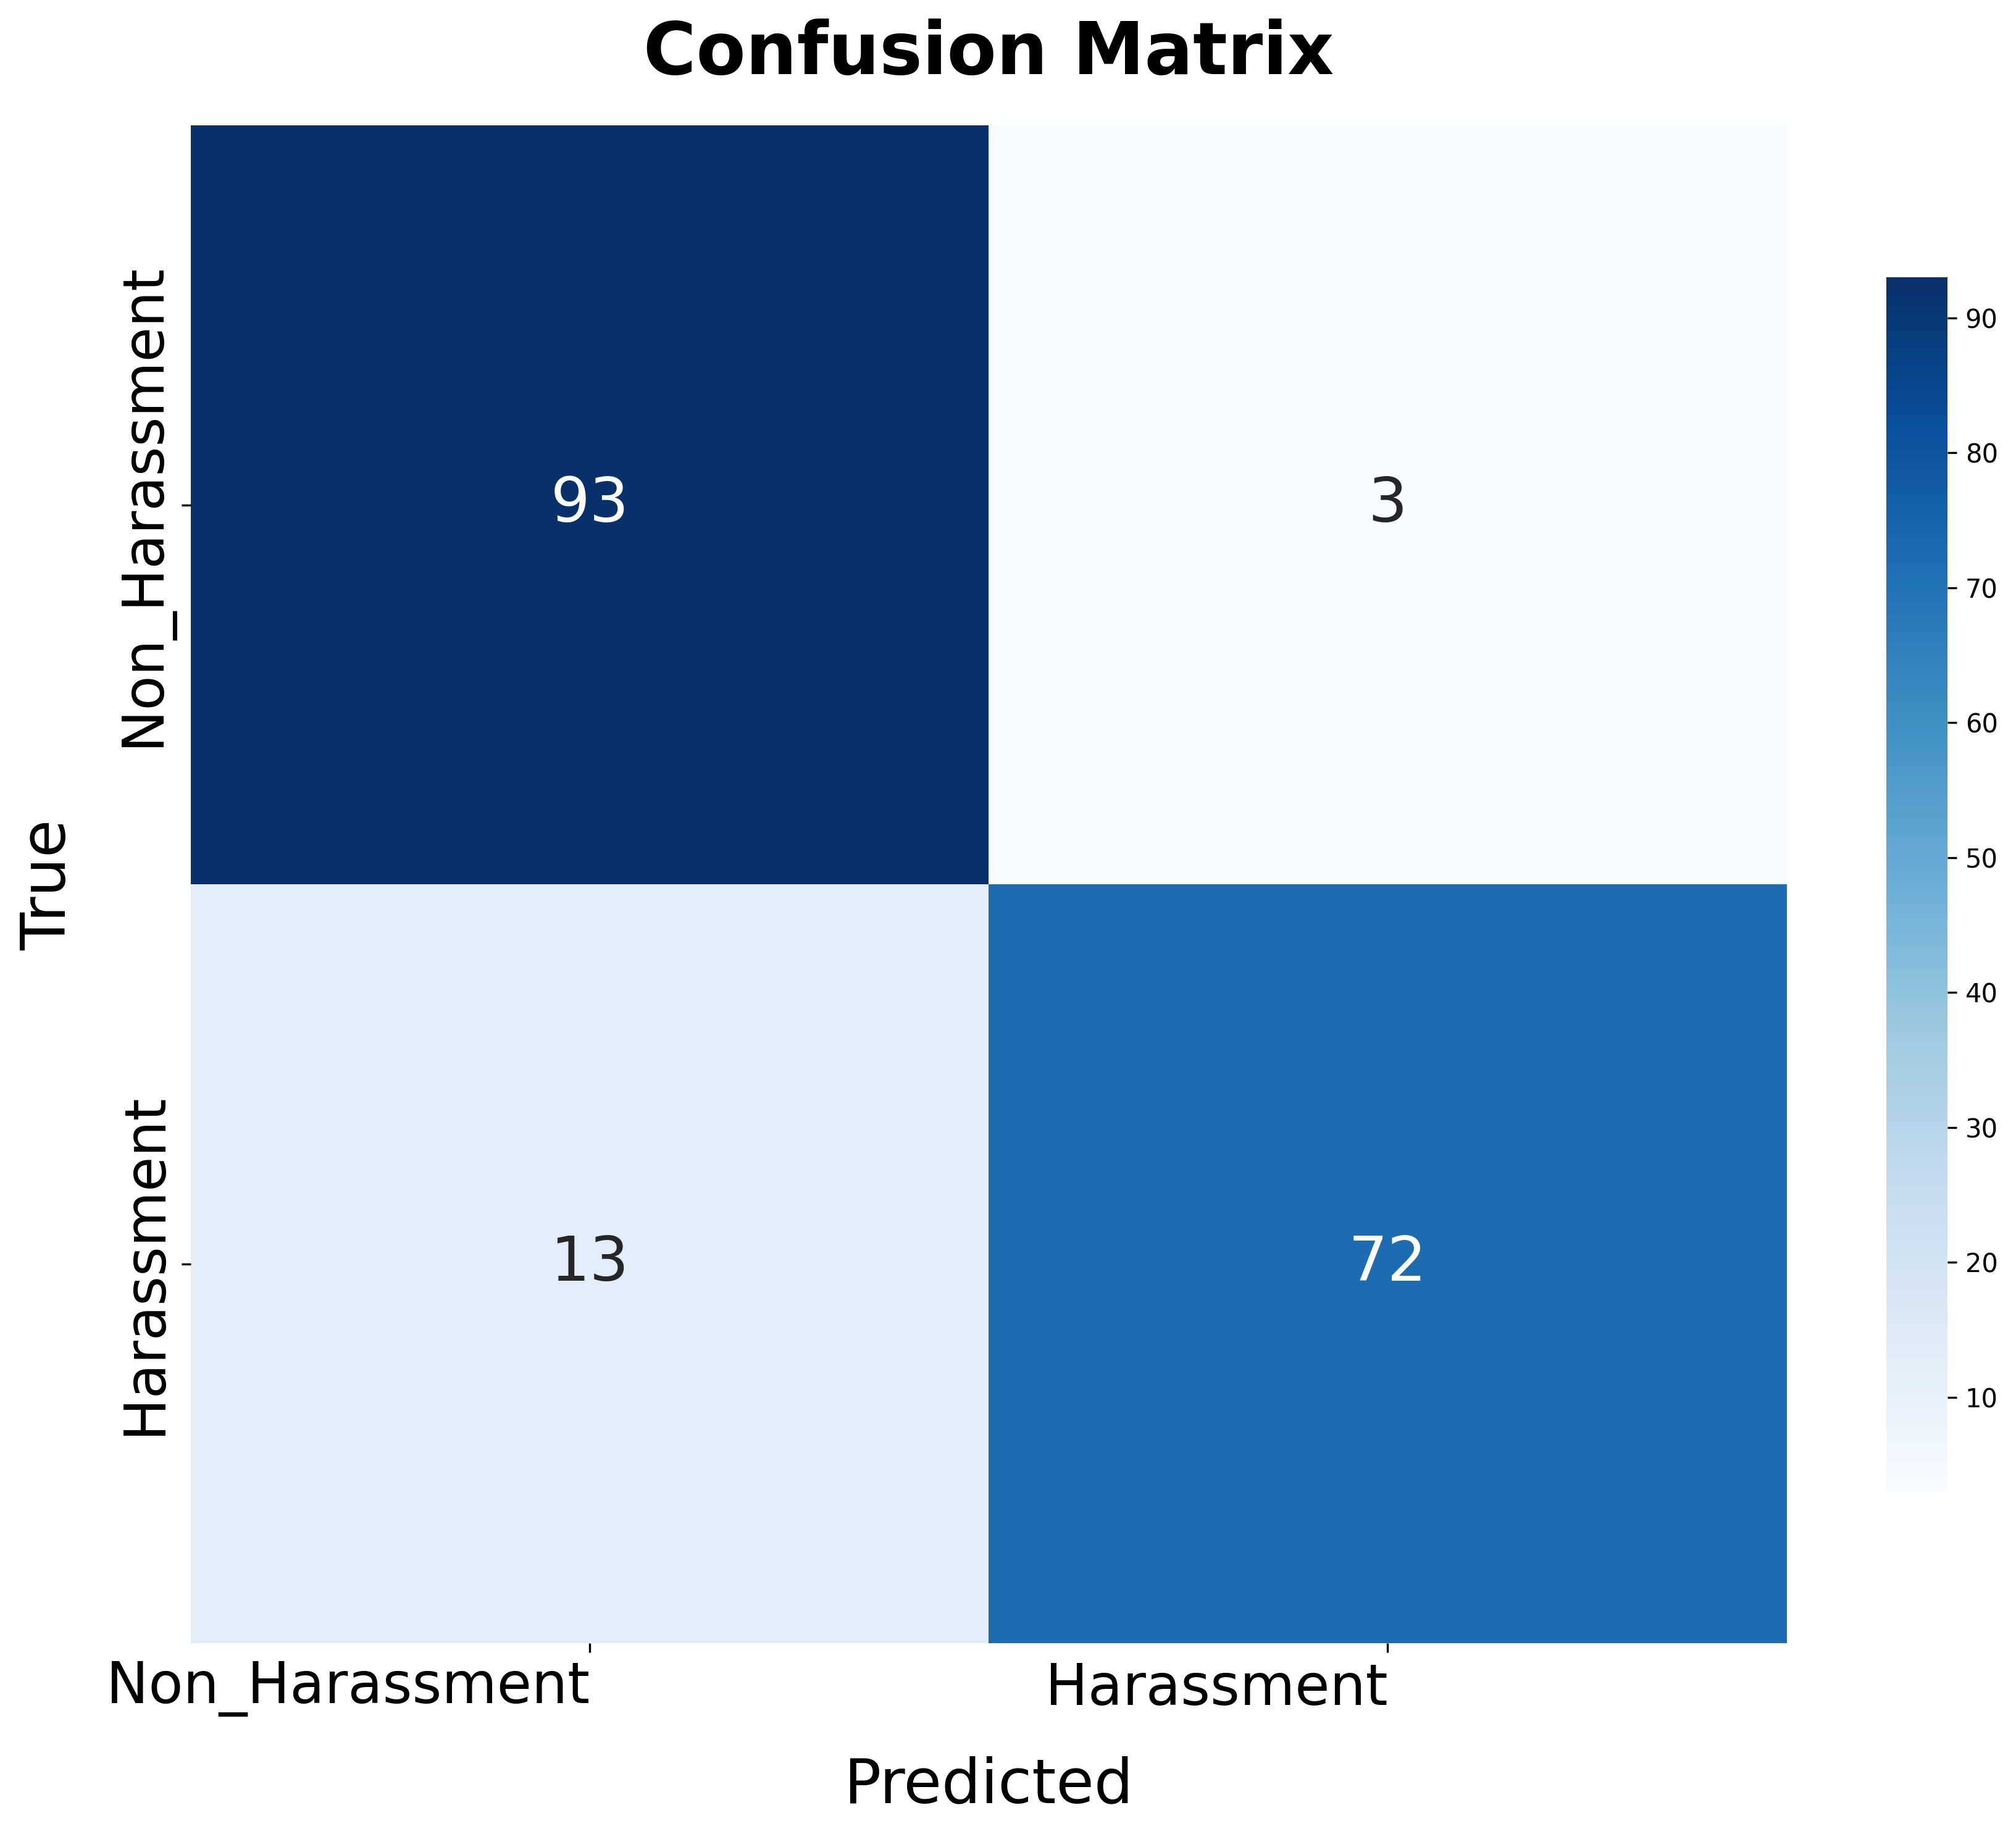

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Improved Confusion Matrix Plot
idx_to_class = {v: k for k, v in label_map.items()}
class_names = list(idx_to_class.values())

cm = confusion_matrix(true_class_names, pred_class_names, labels=class_names)

# === Enhanced Plot Settings ===
plt.figure(figsize=(12, 10), dpi=300)  # Larger size + High DPI

ax = sns.heatmap(cm,
                 annot=True,
                 fmt='d',
                 cmap="Blues",
                 xticklabels=class_names,
                 yticklabels=class_names,
                 annot_kws={"size": 24},      # ← Bigger numbers inside cells
                 cbar_kws={"shrink": 0.8})

# Increase font sizes
plt.title("Confusion Matrix", fontsize=28, fontweight='bold', pad=20)
plt.xlabel("Predicted", fontsize=24, labelpad=15)
plt.ylabel("True", fontsize=24, labelpad=15)

# Bigger tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=22, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), fontsize=22)

plt.tight_layout()   # Clean spacing
plt.show()

In [ ]:
best_epoch

4

Validation Accuracy: 91.16%
Validation Loss: 0.2473

Classification Report:
                precision    recall  f1-score   support

    Harassment      0.960     0.847     0.900        85
Non_Harassment      0.877     0.969     0.921        96

      accuracy                          0.912       181
     macro avg      0.919     0.908     0.910       181
  weighted avg      0.916     0.912     0.911       181



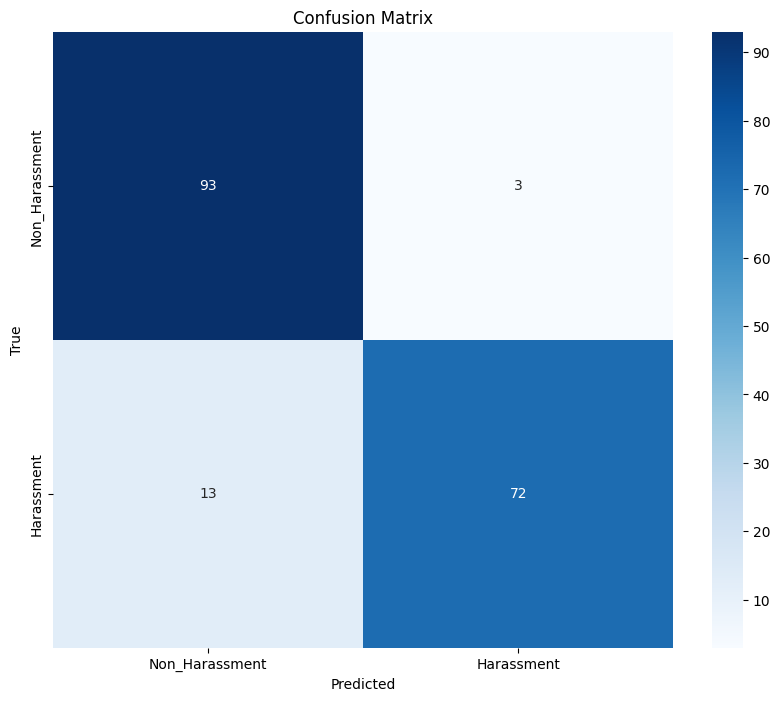

In [ ]:
best_model = f"/content/drive/MyDrive/ModelTrain/Sexual_Harassment/checkpoints/New1/model_epoch_{best_epoch}.pth"

# Load best model
model.load_state_dict(torch.load(best_model))
model.to(device)
model.eval()

# Run evaluation
avg_test_loss, test_acc, report, true_class_names, pred_class_names = evaluate(model, val_loader, label_map, device)

# Print results
print(f"Validation Accuracy: {test_acc * 100:.2f}%")
print(f"Validation Loss: {avg_test_loss:.4f}")
print("\nClassification Report:")
print(report)

# Plot Confusion Matrix
idx_to_class = {v: k for k, v in label_map.items()}
class_names = list(idx_to_class.values())

cm = confusion_matrix(true_class_names, pred_class_names, labels=class_names)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

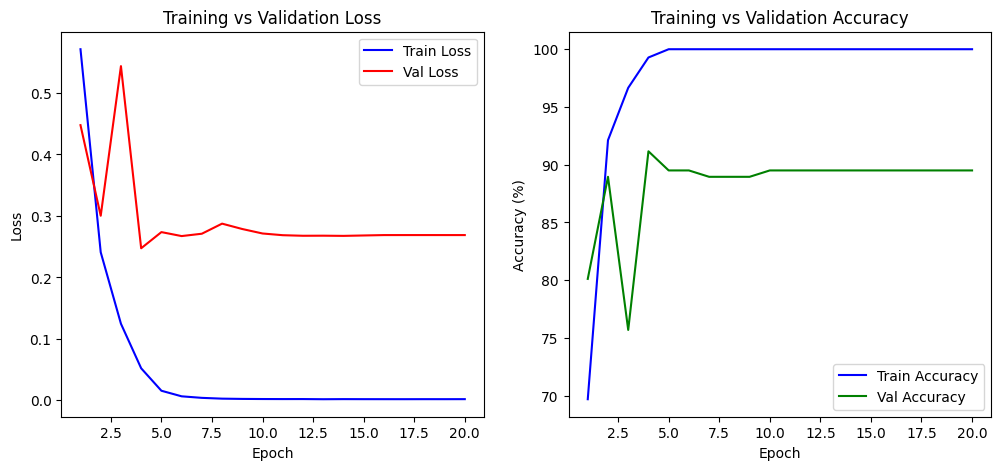

In [ ]:
# =====================
# Plot Loss & Accuracy Curves
# =====================
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12,5))

# ----- Loss Curve -----
plt.subplot(1,2,1)
plt.plot(epochs, train_losses, 'b-', label='Train Loss')
plt.plot(epochs, val_losses, 'r-', label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

# ----- Accuracy Curve -----
plt.subplot(1,2,2)
plt.plot(epochs, train_accuracies, 'b-', label='Train Accuracy')
plt.plot(epochs, val_accuracies, 'g-', label='Val Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

def evaluate_and_plot_roc(y_true, y_score, model_name="Classifier Model"):
    """
    Calculates ROC curve points (FPR, TPR), AUC, and plots the ROC curve.

    Args:
        y_true (array-like): True binary labels (0 or 1).
        y_score (array-like): Target scores (e.g., predicted probabilities of class 1).
        model_name (str): The name of the model for the plot title and legend.

    Returns:
        tuple: (fpr, tpr, roc_auc)
            fpr (array): False Positive Rates
            tpr (array): True Positive Rates
            roc_auc (float): Area Under the Curve
    """
    # 1. Calculate ROC Curve Points
    fpr, tpr, _ = roc_curve(y_true, y_score)

    # 2. Calculate Area Under the Curve (AUC)
    roc_auc = roc_auc_score(y_true, y_score)

    print(f"--- {model_name} Evaluation ---")
    print(f"Area Under the Curve (AUC): {roc_auc:.4f}")

    # 3. Plotting the ROC Curve
    plt.figure(figsize=(8, 6))

    # Plot the ROC curve
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC curve for {model_name} (AUC = {roc_auc:.4f})')

    # Plot the 45-degree line (random classifier benchmark)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
             label='Random Guess (AUC = 0.5)')

    # Set plot labels and title
    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR) / Recall')
    plt.title(f'Receiver Operating Characteristic (ROC) Curve for {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show() # Display the plot

    return fpr, tpr, roc_auc

--- Video Classification Model Evaluation ---
Area Under the Curve (AUC): 0.9661


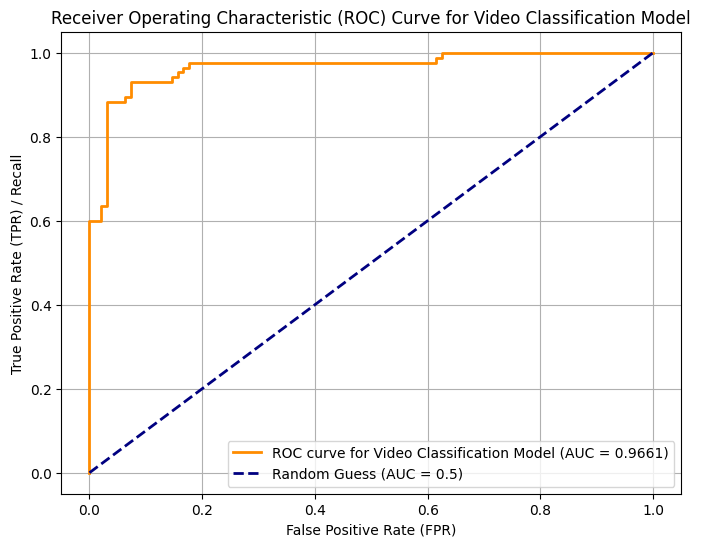

In [ ]:
# Perform evaluation to get true_class_names and all_probs

# Load best model if not already loaded and moved to device
# Assuming model and device are already defined and model is loaded and moved to device in previous cells
# model.load_state_dict(torch.load(best_model)) # Avoid reloading if already done
# model.to(device) # Avoid moving if already done
model.eval() # Ensure model is in evaluation mode

true_labels = []
all_probs = []

# Re-run a simplified evaluation loop to get probabilities and true labels
with torch.no_grad():
    for pixel_values, labels in val_loader:
        pixel_values = pixel_values.to(device)
        labels = labels.to(device)

        outputs = model(pixel_values=pixel_values)

        probs = torch.nn.functional.softmax(outputs.logits, dim=1) # Calculate probabilities
        all_probs.extend(probs.cpu().numpy()) # Store probabilities

        true_labels.extend(labels.cpu().numpy())

# Convert index to class names and binary labels
idx_to_class = {v: k for k, v in label_map.items()}
true_class_names = [idx_to_class[i] for i in true_labels]
all_probs = np.array(all_probs)


# Assuming binary classification with 'No_Harassment' as negative (0) and 'Harassment' as positive (1)
# We need the probabilities of the positive class (Harassment, which is index 1)
harassment_probs = all_probs[:, label_map['Harassment']]
true_labels_binary = [label_map[name] for name in true_class_names] # Convert class names back to binary labels

y_test = true_labels_binary
y_preds_proba = harassment_probs

# Call the function to plot the ROC curve
# Assuming evaluate_and_plot_roc function is defined in a previous cell (IZ9UfHWQbVQB)
fpr, tpr, auc = evaluate_and_plot_roc(y_test, y_preds_proba, model_name="Video Classification Model")

In [ ]:
def predict_video(video_path, model, feature_extractor, label_map, num_frames=32):
    # Load video frames
    vr = VideoReader(video_path, ctx=cpu(0))
    total_frames = len(vr)
    indices = np.linspace(0, total_frames - 1, min(num_frames, total_frames)).astype(int)
    frames = vr.get_batch(indices).asnumpy()

    # Preprocess
    inputs = feature_extractor(list(frames), return_tensors="pt")
    pixel_values = inputs["pixel_values"].to(device)

    # Inference
    with torch.no_grad():
        outputs = model(pixel_values)
        probs = torch.nn.functional.softmax(outputs.logits, dim=1)
        pred_class_idx = torch.argmax(probs, dim=1).item()

    # Map index to class name
    class_name = [k for k, v in label_map.items() if v == pred_class_idx][0]
    confidence = probs[0][pred_class_idx].item()
    return class_name, confidence

In [ ]:
video_path = "/content/Sexual_Harassment_Dataset/Sexual_Harassment_Dataset/test/Harassment/haras_10.mp4"  # <-- change this to your actual file
pred_class, confidence = predict_video(video_path, model, feature_extractor, label_map)
print(f"Predicted: {pred_class} ({confidence*100:.1f}%)")

Predicted: Harassment (67.8%)


In [ ]:
# Re-run the prediction to ensure pred_class and confidence are defined
pred_class, confidence = predict_video(video_path, model, feature_extractor, label_map)

vr = VideoReader(video_path, ctx=cpu(0))
frames = vr.get_batch(np.linspace(0, len(vr)-1, 32).astype(int)).asnumpy()

import matplotlib.pyplot as plt

fig, axs = plt.subplots(8, 4, figsize=(12, 12))
for i, ax in enumerate(axs.flatten()):
    ax.imshow(frames[i])
    ax.axis('off')
plt.suptitle(f"Predicted: {pred_class} ({confidence*100:.1f}%)", fontsize=16)
plt.show()